# Evento Evaluativo 3 · Business Intelligence · E-commerce
## Notebook 01 — Comprensión del problema (Fase 1)

**Grupo 3 · Análisis de Datos · ITM 2026-2 · Docente: Daniel Alexis Nieto Mora**
Integrantes: Santiago Betancur (@Xantyagoh) · Diego Alzate (@DiegoA1123) · Carlos Mendez (@carmarisx) · Sebastian Cadavid (@Exmen9) · Daniel Martinez (@danielmmnez)

**Qué hace este notebook:** describe el contexto del dataset, plantea el problema de negocio, formula las preguntas clave y audita la calidad de los datos *antes* de limpiarlos (la limpieza es del notebook 02).

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Contexto del dataset

**Dataset:** *Online Retail II* — UCI Machine Learning Repository (id 502), donado en 2019 por Daqing Chen.
**Cita:** Chen, D. (2019). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D · Licencia CC BY 4.0.
**Tipo de fuente:** secundaria (no la recolectamos nosotros; son transacciones reales de una empresa).

**Qué contiene:** todas las transacciones de una tienda en línea del Reino Unido, sin local físico, que vende principalmente artículos de regalo para toda ocasión. **Muchos de sus clientes son mayoristas**, y eso condiciona todo el análisis: los pedidos grandes no son "errores", son el modelo de negocio.
**Periodo:** 01/12/2009 a 09/12/2011 (dos años; el último mes está incompleto).

**Por qué este dataset para el Equipo 3 (E-commerce):** tiene el ciclo completo de una tienda en línea (pedido → producto → cliente → país → fecha → cancelación), lo que permite construir dimensiones y métricas de BI reales (ventas, ticket, clientes, recompra, devoluciones) y plantear hipótesis contrastables con muchas observaciones.

In [2]:
# Carga del dataset (el CSV se genera con src/descargar_datos.py)
df = pd.read_csv(RAW, parse_dates=['InvoiceDate'],
                 dtype={'Invoice': 'string', 'StockCode': 'string'})
print('Filas:', f'{df.shape[0]:,}', '| Columnas:', df.shape[1])
print('Memoria (MB):', round(df.memory_usage(deep=True).sum() / 1024**2, 1))
df.head()

Filas: 1,067,371 | Columnas: 8
Memoria (MB): 117.3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  string        
 1   StockCode    1067371 non-null  string        
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(2), string(2)
memory usage: 117.3 MB


### Diccionario de datos

| Variable | Tipo | Significado | Observación |
|---|---|---|---|
| `Invoice` | texto (nominal) | Número de factura (6 dígitos) | Si empieza por **C** es una **cancelación/devolución** |
| `StockCode` | texto (nominal) | Código de producto | Hay códigos que **no son productos** (envío, comisiones, ajustes) |
| `Description` | texto | Nombre del producto | Tiene nulos |
| `Quantity` | entero | Unidades por línea | Negativa en cancelaciones |
| `InvoiceDate` | fecha-hora | Momento de la transacción | Del 2009-12-01 al 2011-12-09 |
| `Price` | decimal | Precio unitario en libras (£) | Hay precios 0 y negativos (ajustes contables) |
| `Customer ID` | decimal (nominal) | Identificador del cliente (5 dígitos) | **~23 % de las líneas no tienen cliente** |
| `Country` | texto (nominal) | País de residencia del cliente | 43 países, el Reino Unido domina |

**Unidad de observación:** una *línea de factura* (un producto dentro de un pedido). Un pedido (`Invoice`) tiene varias líneas.

In [4]:
# Ficha rapida del dataset
ficha = pd.Series({
    'Lineas de factura': f'{len(df):,}',
    'Facturas (pedidos + cancelaciones)': f'{df["Invoice"].nunique():,}',
    'Clientes identificados': f'{df["Customer ID"].nunique():,}',
    'Productos (StockCode)': f'{df["StockCode"].nunique():,}',
    'Paises': df['Country'].nunique(),
    'Primera transaccion': df['InvoiceDate'].min(),
    'Ultima transaccion': df['InvoiceDate'].max(),
}, name='valor').to_frame()
ficha

,valor
Lineas de factura,"1,067,371"
Facturas (pedidos + cancelaciones),"53,628"
Clientes identificados,"5,942"
Productos (StockCode),"5,305"
Paises,43
Primera transaccion,2009-12-01 07:45:00
Ultima transaccion,2011-12-09 12:50:00


## 2. Problema de negocio

La empresa vende regalos a mayoristas y consumidores en 43 países, con **ingresos que dependen de pocos meses fuertes y de un grupo reducido de clientes**. La gerencia necesita decidir con evidencia, no con intuición:

1. **Cuándo y cuánto reforzar** inventario y marketing (¿qué tan marcada es la temporada alta?).
2. **A quién cuidar**: qué clientes y mercados sostienen el ingreso y cuántos se pierden después de la primera compra.
3. **Dónde se pierde dinero**: qué tan grandes son las devoluciones/cancelaciones y si se concentran en algún segmento.

**Objetivo del proyecto:** convertir las transacciones en información útil para la toma de decisiones mediante un modelo de datos, KPIs, pruebas de hipótesis y un dashboard ejecutivo en Power BI.

## 3. Preguntas clave

| # | Pregunta | Qué necesitamos medir |
|---|---|---|
| **P1** | ¿Cómo evolucionan las ventas en el tiempo y qué tan fuerte es la estacionalidad? | Ingresos por semana/mes, comparación temporada alta vs resto |
| **P2** | ¿Qué tan concentrados están los ingresos en pocos clientes, productos y países? | Curva de Pareto, participación del top 20 % |
| **P3** | ¿Qué proporción de clientes vuelve a comprar y qué diferencia a quienes lo hacen? | Tasa de recompra a 90 días, cohortes, RFM |
| **P4** | ¿Qué tan grandes son las devoluciones y dónde se concentran? | Valor devuelto / ventas brutas, por país y mes |
| **P5** | ¿Los clientes del exterior se comportan distinto a los del Reino Unido? | Ticket promedio, tasa de cancelación y recompra por mercado |

Cada pregunta se conectará más adelante con una **hipótesis** (notebook 04), un **KPI** (notebook 05) y una **página del dashboard**.

In [5]:
trazabilidad = pd.DataFrame([
    ('P1', 'Estacionalidad', 'H1, H5', 'Ingresos netos',               'InvoiceDate, Quantity, Price'),
    ('P2', 'Concentracion', '-',  'Concentracion del ingreso',     'Customer ID, StockCode, Country'),
    ('P3', 'Retencion',     'H4, H5, H6', 'Tasa de recompra a 90 dias', 'Customer ID, Invoice, InvoiceDate'),
    ('P4', 'Devoluciones',  'H3', 'Tasa de devolucion',            'Invoice (prefijo C), Quantity, Price'),
    ('P5', 'Mercados',      'H2, H3, H6', 'Ticket promedio',       'Country, Invoice, Quantity, Price'),
], columns=['Pregunta', 'Tema', 'Hipotesis', 'KPI principal', 'Variables del dataset'])
trazabilidad

,Pregunta,Tema,Hipotesis,KPI principal,Variables del dataset
0,P1,Estacionalidad,"H1, H5",Ingresos netos,"InvoiceDate, Quantity, Price"
1,P2,Concentracion,-,Concentracion del ingreso,"Customer ID, StockCode, Country"
2,P3,Retencion,"H4, H5, H6",Tasa de recompra a 90 dias,"Customer ID, Invoice, InvoiceDate"
3,P4,Devoluciones,H3,Tasa de devolucion,"Invoice (prefijo C), Quantity, Price"
4,P5,Mercados,"H2, H3, H6",Ticket promedio,"Country, Invoice, Quantity, Price"


## 4. Auditoría inicial de calidad (antes de limpiar)

Antes de decidir qué limpiar hay que **medir** qué tan sucios están los datos. Aquí solo diagnosticamos; las decisiones de limpieza las ejecuta el notebook 02.

In [6]:
d = df.rename(columns={'Customer ID': 'customer_id'}).copy()
d['es_cancelacion'] = d['Invoice'].str.startswith('C')
d['importe'] = d['Quantity'] * d['Price']

# Codigos de stock que NO son productos reales (envio, comisiones, ajustes, pruebas...)
patron_producto = r'^\d{5}|^DCGS|^gift_'
d['no_producto'] = ~d['StockCode'].str.match(patron_producto)

nulos = d.isna().sum().rename('nulos').to_frame()
nulos['% nulos'] = (nulos['nulos'] / len(d) * 100).round(2)
nulos[nulos['nulos'] > 0]

,nulos,% nulos
Description,4382,0.41
customer_id,243007,22.77


In [7]:
ventas_pos = d[(~d['es_cancelacion']) & (d['Quantity'] > 0) & (d['Price'] > 0)]
auditoria = pd.DataFrame({
    'problema': [
        'Lineas duplicadas exactas',
        'Cancelaciones (factura con C)',
        'Precio <= 0',
        'Cantidad <= 0 sin ser cancelacion',
        'Codigo de stock que no es producto',
        'Sin Customer ID',
    ],
    'filas': [
        int(d.duplicated().sum()),
        int(d['es_cancelacion'].sum()),
        int((d['Price'] <= 0).sum()),
        int(((d['Quantity'] <= 0) & ~d['es_cancelacion']).sum()),
        int(d['no_producto'].sum()),
        int(d['customer_id'].isna().sum()),
    ],
})
auditoria['% del total'] = (auditoria['filas'] / len(d) * 100).round(2)
auditoria

,problema,filas,% del total
0,Lineas duplicadas exactas,34335,3.22
1,Cancelaciones (factura con C),19494,1.83
2,Precio <= 0,6207,0.58
3,Cantidad <= 0 sin ser cancelacion,3457,0.32
4,Codigo de stock que no es producto,5835,0.55
5,Sin Customer ID,243007,22.77


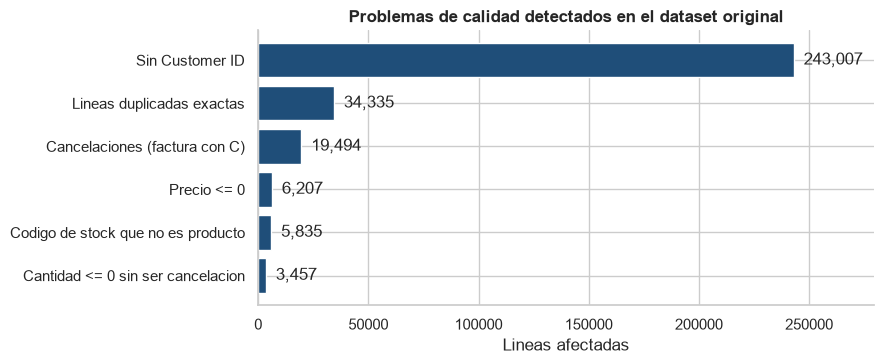

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
orden = auditoria.sort_values('filas')
ax.barh(orden['problema'], orden['filas'], color=AZUL)
for i, v in enumerate(orden['filas']):
    ax.text(v, i, f'  {v:,}', va='center')
ax.set_title('Problemas de calidad detectados en el dataset original')
ax.set_xlabel('Lineas afectadas')
ax.set_xlim(0, orden['filas'].max() * 1.15)
plt.tight_layout()
plt.savefig(FIG / '01_auditoria_calidad.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Cuanto dinero hay en las lineas sin cliente? (decide si se pueden descartar)
ingreso_total = ventas_pos['importe'].sum()
ingreso_sin_cliente = ventas_pos.loc[ventas_pos['customer_id'].isna(), 'importe'].sum()
print(f'Ingreso bruto (ventas validas): £{ingreso_total:,.0f}')
print(f'Ingreso en lineas SIN cliente : £{ingreso_sin_cliente:,.0f}  ({ingreso_sin_cliente/ingreso_total:.1%})')

# Las cancelaciones: cuanto valen y a que facturas pertenecen
canc = d[d['es_cancelacion']]
print(f'\nCancelaciones: {canc["Invoice"].nunique():,} facturas, valor £{canc["importe"].sum():,.0f}')
print(f'Valor cancelado / ingreso bruto: {-canc["importe"].sum()/ingreso_total:.1%}')

Ingreso bruto (ventas validas): £20,972,595
Ingreso en lineas SIN cliente : £3,229,165  (15.4%)

Cancelaciones: 8,292 facturas, valor £-1,526,668
Valor cancelado / ingreso bruto: 7.3%


### Qué encontramos y qué haremos (entrega al Integrante 2)

| Hallazgo | Magnitud | Decisión para la Fase 3 |
|---|---|---|
| Duplicados exactos | 34.335 líneas (3,2 %) | Eliminar: inflan ventas |
| Códigos que no son producto (envío, comisiones, ajustes) | 5.835 líneas (0,6 %) | Eliminar: no son mercancía |
| Precio ≤ 0 y cantidad ≤ 0 sin ser cancelación | 6.207 y 3.457 líneas | Eliminar: ajustes contables, no ventas |
| Cancelaciones (factura con C) | 19.494 líneas (1,8 %) | **Conservar** como devoluciones |
| Sin `Customer ID` | 22,8 % de las líneas, **15,4 % del ingreso** | **Conservar** para ventas; excluir de análisis por cliente |

**Advertencia sobre la tasa de devolución:** con los datos *sin limpiar* el valor cancelado parece ser el **7,3 %** de las ventas. Es una cifra inflada: incluye ajustes contables y códigos que no son producto. Después de limpiar (notebook 02) la tasa real baja a ~2,4 %. Moraleja: un KPI calculado sobre datos sucios puede llevar a una decisión equivocada.